# FinSight — Multi-Agent Financial Analysis System
### AAI-520 · University of San Diego · Final Team Project

**Team 3:** Hivanshu Kapania · Karthik K · Navneet Kumar  
**Project:** FinSight — Multi-Agent Financial Analysis System  
**GitHub repository:** https://github.com/karthik1997/finsight-multi-agent-financial-analysis

> **Execution notice:** The outputs embedded in this document were obtained by actually running the offline demonstration using **fictional data**. They do **not** represent downloaded FinQA evaluations, real market prices, or outputs from a downloaded Hugging Face LLM. The same notebook includes an optional network-enabled **FinQA + Hugging Face** evaluation workflow for your team's Colab execution.

## Executive Summary

FinSight implements an investment research *agentic* prototype that:

1. **Plans** question-specific steps and selects a specialist.
2. **Acts** using retrieval, classification, summarization, safe arithmetic, and optional market snapshot tools.
3. **Reflects** through an evaluator–optimizer with an additional retrieval iteration on failure.
4. **Learns across runs** by persisting small feedback notes and using them to adjust retrieval depth.

The three required workflow patterns are operational:
**prompt chaining**, **routing**, and **evaluator–optimizer**. The system is read-only; it never executes trades.

## 1. Task Requirements and Team Responsibilities

| Rubric section | Implementation | Verification |
|---|---|---|
| Agent functions (33.8%) | `InvestmentResearchAgent.plan`, `ToolRegistry`, `evaluate`, `AnalysisMemory` | Plan, tool trace, memory before/after |
| Workflow patterns (33.8%) | News prompt chain; specialist `detect_specialist`; evaluator–optimizer refinement | Five-stage news log; earnings/news/market routes; iteration log |
| Code (32.4%) | Self-contained notebook, typed classes, tools, FinQA converter, tests, outputs | Executed offline demonstrations and tests |

**Division of planned responsibilities from the Module 4 status form:**

- **Hivanshu Kapania — Data and Retrieval:** FinQA ingestion, text/table processing, embeddings/retrieval, retrieval evaluation.
- **Karthik K — Architecture and Orchestration:** agent planner/router, pipeline integration, verification/guardrails, evidence-grounded synthesis.
- **Navneet Kumar — Numerical Reasoning and Evaluation:** financial metrics, Hugging Face model experiments, safe calculator, answer/error evaluation.

These are *planned contributions from the status form*, not a claim that GitHub commits or individual contributions have already been verified. Each teammate should review, run, and customize their sections before final submission.

## 2. Architecture and Data Flow

```text
Question + Symbol
      |
 Planner + Previous Memory Notes
      |
 Specialist Router ---------------------------+
      |                |                       |
 Earnings Analyst     News Analyst            Market Analyst
      |                |                       |
 FinQA / reports      NEWS CHAIN              Read-only quote tool
      |                |                       |
 Search / retrieve    Ingest -> Preprocess    Evidence lookup
      |                |                       |
      |               Classify -> Extract      |
      |                |                       |
      |               Summarize                |
      +----------------+-----------------------+
                       |
                 Draft Response
                       |
               Grounding Evaluator
                       |
             PASS? ----+---- NO
               |             |
             Answer      Widen retrieval
               |             |
               |         Re-generate / Re-evaluate
               +-------------+
                       |
              Persist brief feedback
```

**Tool trust boundaries:** retrieved documents are untrusted data; the calculator uses an AST whitelist rather than unrestricted `eval`; no tools have trading or brokerage write access. The source-label validator checks cited document IDs but cannot guarantee every assertion is factually supported. Human review remains necessary.

## 3. Configuration and Reproducibility

The default mode runs without downloading anything. To run the **real FinQA evaluation in Google Colab**, set the following booleans to `True` and execute all cells. An internet connection is necessary.

**Dataset provenance:** FinQA GitHub repository: https://github.com/czyssrs/FinQA. Official dataset JSON splits `train.json`, `dev.json`, and `test.json`. Gold answers/programs are held separately from retrieved evidence to prevent oracle leakage.

In [1]:
RUN_REAL_FINQA = False             # Change to True in Colab for actual FinQA data
USE_SENTENCE_EMBEDDINGS = False    # Requires sentence-transformers download
USE_LOCAL_HF_LLM = False           # Requires transformers + flan-t5-small weights
INSTALL_OPTIONAL_PACKAGES = False # Change to True to install dependencies in Colab
FINQA_RECORD_LIMIT = 100          # Runtime-constrained dev subset, not leaderboard
FINQA_EVAL_QUESTIONS = 8          # Number of sampled generation evaluations

if INSTALL_OPTIONAL_PACKAGES:
    import subprocess
    import sys
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "sentence-transformers>=3.0", "transformers>=4.44,<6",
        "sentencepiece>=0.2", "yfinance>=0.2"
    ])

print("Execution configuration:")
print({"run_real_finqa": RUN_REAL_FINQA,
       "sentence_embeddings": USE_SENTENCE_EMBEDDINGS,
       "huggingface_llm": USE_LOCAL_HF_LLM,
       "dataset_limit": FINQA_RECORD_LIMIT})

Execution configuration:
{'run_real_finqa': False, 'sentence_embeddings': False, 'huggingface_llm': False, 'dataset_limit': 100}


## 4. Core Imports, Documents and Tool Registry

The notebook contains the full source directly. The registry records every tool invocation and its arguments. Tools are called dynamically based on the selected specialist, question, and evaluator feedback.

In [2]:
from __future__ import annotations

import ast
import hashlib
import json
import math
import operator
import os
import re
from collections import Counter
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
@dataclass
class ResearchDocument:
    doc_id: str
    symbol: str
    kind: str
    title: str
    content: str
    source: str
    published: str = "unknown"
    metadata: Dict[str, Any] = field(default_factory=dict)

    def display(self) -> str:
        return f"[{self.doc_id}] ({self.kind}; {self.source}) {self.title}: {self.content}"

@dataclass
class ToolEvent:
    tool: str
    parameters: Dict[str, Any]
    outcome: str

class ToolRegistry:
    def __init__(self):
        self.tools: Dict[str, Any] = {}
        self.events: List[ToolEvent] = []

    def register(self, name: str, func: Any) -> None:
        self.tools[name] = func

    def call(self, name: str, **kwargs) -> Any:
        if name not in self.tools:
            raise KeyError(f"Unknown tool: {name}")
        try:
            result = self.tools[name](**kwargs)
            preview = str(result)
            self.events.append(ToolEvent(name, kwargs, preview[:160]))
            return result
        except Exception as exc:
            self.events.append(ToolEvent(name, kwargs, f"ERROR: {exc}"))
            raise

## 5. Retrieval and Restricted Calculator

The retriever supports semantic sentence-transformer embeddings (`all-MiniLM-L6-v2`) in real-data mode and a fully executable TF-IDF vector-space baseline offline. Similarity and top-k results are explicit; these backends are not presented as equivalent.

`safe_calculate` parses a small arithmetic grammar; Python imports, function calls, identifiers and attributes are rejected.

In [4]:
class SemanticRetriever:
    """Vector-space semantic retriever: sentence embeddings if available; TF-IDF otherwise.

    No benchmark claim is made about TF-IDF: it is an offline lexical baseline.
    """
    def __init__(self, docs: List[ResearchDocument], embedding_backend="tfidf",
                 model_name="sentence-transformers/all-MiniLM-L6-v2"):
        self.docs = list(docs)
        self.backend = "tfidf"
        self.encoder = None
        self.vectorizer = None
        texts = [f"{d.title}. {d.content}" for d in docs]
        if embedding_backend == "sentence_transformer":
            from sentence_transformers import SentenceTransformer
            self.encoder = SentenceTransformer(model_name)
            self.vectors = np.asarray(self.encoder.encode(texts, normalize_embeddings=True))
            self.backend = f"sentence_transformer ({model_name})"
        else:
            self.vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words="english")
            self.vectors = self.vectorizer.fit_transform(texts)

    def retrieve(self, query: str, top_k: int = 3,
                 symbol: Optional[str] = None, kind: Optional[str] = None) -> List[Dict[str, Any]]:
        eligible = [i for i, d in enumerate(self.docs)
                    if (not symbol or d.symbol.upper() == symbol.upper())
                    and (not kind or d.kind == kind)]
        if not eligible:
            return []
        if self.encoder is not None:
            q = self.encoder.encode([query], normalize_embeddings=True)
            scores = (self.vectors[eligible] @ q[0]).tolist()
        else:
            q = self.vectorizer.transform([query])
            scores = cosine_similarity(q, self.vectors[eligible]).ravel().tolist()
        ranked = sorted(zip(eligible, scores), key=lambda x: x[1], reverse=True)[:top_k]
        return [{"document": self.docs[idx], "score": float(score)} for idx, score in ranked]

In [5]:
_ALLOWED_BINOPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
                  ast.Div: operator.truediv, ast.Pow: operator.pow}
_ALLOWED_UNARY = {ast.UAdd: operator.pos, ast.USub: operator.neg}

def safe_calculate(expression: str) -> float:
    """Evaluate arithmetic only: no function calls, variables, attributes, or Python execution."""
    if len(expression) > 120:
        raise ValueError("Expression too long")
    tree = ast.parse(expression, mode="eval")

    def walk(node, depth=0):
        if depth > 14:
            raise ValueError("Expression nesting too deep")
        if isinstance(node, ast.Expression):
            return walk(node.body, depth + 1)
        if isinstance(node, ast.Constant) and type(node.value) in (float, int):
            if abs(node.value) > 1e12:
                raise ValueError("Literal magnitude too large")
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_BINOPS:
            left, right = walk(node.left, depth + 1), walk(node.right, depth + 1)
            if isinstance(node.op, ast.Pow) and (abs(right) > 8 or abs(left) > 1e6):
                raise ValueError("Unsafe exponentiation")
            return _ALLOWED_BINOPS[type(node.op)](left, right)
        if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_UNARY:
            return _ALLOWED_UNARY[type(node.op)](walk(node.operand, depth + 1))
        raise ValueError("Unsafe calculation")

    result = float(walk(tree))
    if not math.isfinite(result):
        raise ValueError("Nonfinite result")
    return result

## 6. Workflow Pattern 1 — Prompt Chaining

The required linear sequence is implemented as separately testable functions: **Ingest News → Preprocess → Classify → Extract → Summarize**. Financial keywords and amounts are extracted from provided documents. This is an auditable baseline that could be replaced by an LLM classifier in later iterations.

In [6]:
def ingest_news(documents: Iterable[ResearchDocument]) -> List[ResearchDocument]:
    return [d for d in documents if d.kind == "news"]

def preprocess_news(documents: Iterable[ResearchDocument]) -> List[ResearchDocument]:
    return [ResearchDocument(**{**d.__dict__, "content": " ".join(d.content.split())})
            for d in documents]

def classify_news(documents: Iterable[ResearchDocument]) -> List[Dict[str, Any]]:
    labels = {"earnings": ["earnings", "revenue", "profit", "quarter", "results"],
              "market": ["price", "share", "stock", "market", "volume"],
              "risk": ["recall", "lawsuit", "investigation", "risk", "regulator"]}
    classified = []
    for d in documents:
        t = (d.title + " " + d.content).lower()
        counts = {k: sum(w in t for w in v) for k, v in labels.items()}
        cls = max(counts, key=counts.get) if max(counts.values()) else "general"
        classified.append({"document": d, "category": cls})
    return classified

def extract_news(items: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    extracted = []
    for item in items:
        text = item["document"].content
        figures = re.findall(r"(?<![\w])(?:\$\s*)?\d[\d,]*(?:\.\d+)?\s*(?:%|million|billion)?", text, flags=re.I)
        extracted.append({**item, "figures": figures[:12]})
    return extracted

def summarize_news(items: List[Dict[str, Any]], max_items=3) -> str:
    if not items:
        return "No relevant news articles are available in the supplied corpus."
    summaries = []
    for item in items[:max_items]:
        d = item["document"]
        first = re.split(r"(?<=[.!?])\s+", d.content, maxsplit=1)[0]
        summaries.append(f"[{d.doc_id}] {d.title}: {first} (category: {item['category']})")
    return "\n".join(summaries)

def news_prompt_chain(documents: List[ResearchDocument]) -> Dict[str, Any]:
    """Required workflow: ingest -> preprocess -> classify -> extract -> summarize."""
    trace = []
    x = ingest_news(documents)
    trace.append({"stage": "Ingest News", "count": len(x)})
    x = preprocess_news(x)
    trace.append({"stage": "Preprocess", "count": len(x)})
    y = classify_news(x)
    trace.append({"stage": "Classify", "labels": [r["category"] for r in y]})
    z = extract_news(y)
    trace.append({"stage": "Extract", "figure_counts": [len(r["figures"]) for r in z]})
    final = summarize_news(z)
    trace.append({"stage": "Summarize", "chars": len(final)})
    return {"summary": final, "items": z, "trace": trace}

## 7. Workflow Pattern 2 — Routing and Cross-Run Memory

The coordinator sends queries to earnings, news, or market specialists. Notes from a failed run expand retrieval depth when a similar symbol is researched again. These notes contain only status, specialist, and feedback — not source passages or credentials.

In [7]:
def detect_specialist(question: str, preferred_kind: Optional[str] = None) -> str:
    """Content routing (not fixed routing for every query)."""
    if preferred_kind in {"earnings", "news", "market"}:
        return preferred_kind
    q = question.lower()
    if any(w in q for w in ("news", "headline", "article", "announcement")):
        return "news"
    if any(w in q for w in ("share price", "stock price", "market price", "volatility", "quote", "volume")):
        return "market"
    return "earnings"

class AnalysisMemory:
    """Short local notes, with timestamps and no storage of retrieved document text."""
    def __init__(self, path: str):
        self.path = Path(path)
        if self.path.exists():
            try:
                self.notes = json.loads(self.path.read_text(encoding="utf-8"))
            except (ValueError, OSError):
                self.notes = {}
        else:
            self.notes = {}

    def recall(self, symbol: str) -> List[Dict[str, Any]]:
        return list(self.notes.get(symbol.upper(), []))[-3:]

    def store(self, symbol: str, specialist: str, outcome: str, feedback: str) -> None:
        key = symbol.upper()
        self.notes.setdefault(key, []).append({
            "time": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "specialist": specialist,
            "outcome": outcome[:80],
            "feedback": feedback[:140],
        })
        self.notes[key] = self.notes[key][-12:]
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.path.write_text(json.dumps(self.notes, indent=2), encoding="utf-8")

## 8. Optional Hugging Face Generator

When `USE_LOCAL_HF_LLM=True`, the system uses a real pretrained encoder–decoder LLM (`google/flan-t5-small`) through `AutoTokenizer` and `AutoModelForSeq2SeqLM` (not the deprecated `text2text-generation` pipeline). A second constrained output can propose a numerical expression to the restricted calculator.

In the **offline demonstration**, no model weights are loaded and the agent explicitly uses an extractive arithmetic baseline. This is useful for verifying orchestration but does **not** constitute evidence of actual LLM performance.

In [8]:
class LocalLLM:
    """Optional genuine local HF encoder-decoder LLM. Run in a networked Colab environment."""
    def __init__(self, model_name="google/flan-t5-small"):
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        import torch
        self.torch = torch
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.model.to(self.device).eval()
        self.model_name = model_name

    def generate(self, prompt: str, max_new_tokens=150) -> str:
        encoded = self.tokenizer(prompt, return_tensors="pt", truncation=True,
                                 max_length=512).to(self.device)
        with self.torch.no_grad():
            output = self.model.generate(**encoded, max_new_tokens=max_new_tokens,
                                         do_sample=False)
        return self.tokenizer.decode(output[0], skip_special_tokens=True).strip()

## 9. Agent Functions and Workflow Pattern 3 — Evaluator–Optimizer

The agent autonomously (within a bounded, read-only policy):

1. Determines the specialist and plans research steps.
2. Calls retrieval and additional tools according to the task.
3. Generates a grounded response or abstains.
4. Evaluates citation IDs, numeric computation and minimum question coverage.
5. On failure, widens retrieval once and compares evaluation scores.
6. Persists a feedback note and modifies retrieval depth on the next run.

**Limitation:** structural citation checking and calculator execution are *not* proofs that all model-generated claims are faithful to their sources. Manual auditing is recommended.

In [9]:
class InvestmentResearchAgent:
    """Planner + dynamic tools + specialist routing + evaluator-optimizer + memory."""
    def __init__(self, documents: List[ResearchDocument], memory_path: str,
                 embedding_backend="tfidf", llm: Optional[Any] = None,
                 quotes: Optional[Dict[str, Dict[str, Any]]] = None):
        self.documents = list(documents)
        self.retriever = SemanticRetriever(self.documents, embedding_backend=embedding_backend)
        self.memory = AnalysisMemory(memory_path)
        self.llm = llm
        self.quotes = quotes or {}
        self.registry = ToolRegistry()
        self.registry.register("retrieve", self.retriever.retrieve)
        self.registry.register("news_chain", lambda symbol: news_prompt_chain(
            [d for d in self.documents if d.symbol.upper() == symbol.upper()]))
        self.registry.register("quote_lookup", lambda symbol: self.quotes.get(symbol.upper()))
        self.registry.register("calculator", safe_calculate)

    @staticmethod
    def plan(symbol: str, question: str, specialist: str, previous_notes: List[Dict[str, Any]]) -> List[str]:
        steps = [f"Classify task and route to {specialist} specialist",
                 f"Retrieve grounded evidence for {symbol} and question",
                 "Extract relevant numerical facts and consult tools if needed",
                 "Generate concise answer with explicit evidence identifiers",
                 "Evaluate grounding, question coverage, and arithmetic consistency"]
        if previous_notes:
            steps.append("Use previous feedback notes to improve result")
        steps.append("Refine once on failure; retain short feedback memory")
        return steps

    def _evidence_answer(self, question: str, hits: List[Dict[str, Any]], specialist: str,
                         symbol: str) -> Dict[str, Any]:
        if not hits or (hits[0]["score"] < 0.045 and specialist != "news"):
            return {"answer": "Insufficient evidence in the available sources.",
                    "source_ids": [], "calculation": None, "abstained": True}
        content = "\n".join(row["document"].display()[:850] for row in hits[:3])
        source_ids = [h["document"].doc_id for h in hits[:3]]

        # A model can synthesize from retrieved text, but source IDs are enforced downstream.
        if self.llm is not None:
            prompt = ("You are a cautious financial-research assistant. Answer only from the "
                      "EVIDENCE. If the evidence is inadequate, say 'Insufficient evidence'. "
                      "Do not invent figures, dates, source IDs, or citations. "
                      "Show a short computation if applicable.\n"
                      f"QUESTION: {question}\nEVIDENCE:\n{content}\nANSWER:")
            answer = self.llm.generate(prompt)
            abstained = "insufficient evidence" in answer.lower() or not answer.strip()
            calculation = None
            # A second, constrained tool-use pass is attempted for numerical questions.
            # The expression is NOT trusted until a restricted calculator evaluates it.
            if not abstained and re.search(r"\b(percentage|percent|how much|ratio|change)\b", question, re.I):
                eq_prompt = ("From the evidence below, return only one numerical Python arithmetic "
                             "expression that answers the question, such as "
                             "(250-200)/200*100. No variables or function calls. "
                             "Return NONE if not enough evidence.\n" 
                             f"QUESTION: {question}\nEVIDENCE: {content[:1200]}\nEXPRESSION:")
                candidate = self.llm.generate(eq_prompt, max_new_tokens=55).strip()
                candidate = candidate.removeprefix("EXPRESSION:").strip().splitlines()[0]
                candidate = candidate.rstrip(". ")
                if candidate != "NONE":
                    try:
                        value = self.registry.call("calculator", expression=candidate)
                        calculation = {"expression": candidate, "value": value}
                        answer += f" [Calculator result: {value:.4g} from {candidate}]"
                    except (ValueError, SyntaxError, ZeroDivisionError, OverflowError):
                        pass
            return {"answer": answer or "Insufficient evidence in the available sources.",
                    "source_ids": [] if abstained else source_ids,
                    "calculation": calculation, "abstained": abstained}

        # Fully labeled synthetic demonstration only; NOT FinQA benchmark prediction.
        primary = hits[0]["document"]
        if primary.metadata.get("demo_arithmetic") and ("percent" in question.lower() or "percentage" in question.lower()):
            v = primary.metadata["demo_arithmetic"]
            expr = f"({v['later']}-{v['earlier']})/{v['earlier']}*100"
            result = self.registry.call("calculator", expression=expr)
            text = (f"Revenue increased from ${v['earlier']:,.0f} million in {v['earlier_year']} "
                    f"to ${v['later']:,.0f} million in {v['later_year']}, "
                    f"a change of {result:.2f}% (calculated as {expr}).")
            return {"answer": text, "source_ids": [primary.doc_id],
                    "calculation": {"expression": expr, "value": result}, "abstained": False}
        if specialist == "news":
            chain = self.registry.call("news_chain", symbol=symbol)
            if chain["items"]:
                return {"answer": chain["summary"],
                        "source_ids": [r["document"].doc_id for r in chain["items"][:3]],
                        "calculation": None, "abstained": False}
        if specialist == "market":
            quote = self.registry.call("quote_lookup", symbol=symbol)
            if quote:
                return {"answer": f"Reference market snapshot: {quote} (offline snapshot; not live pricing).",
                        "source_ids": [f"snapshot-{symbol}"], "calculation": None,
                        "abstained": False}
        # An extractive fallback can present evidence, but MUST NOT invent computed answers.
        return {"answer": f"Evidence retrieved; numerical conclusion not independently verified: "
                          f"{primary.content[:250]}",
                "source_ids": [primary.doc_id], "calculation": None, "abstained": False}

    @staticmethod
    def evaluate(question: str, answer: Dict[str, Any], hits: List[Dict[str, Any]]) -> Dict[str, Any]:
        if answer["abstained"]:
            return {"score": 0.5, "passed": False,
                    "feedback": "No supported answer; retrieve more evidence or request review."}
        valid_ids = {row["document"].doc_id for row in hits}
        cited_ids = set(answer.get("source_ids", []))
        citation_ok = bool(cited_ids) and cited_ids.issubset(valid_ids.union(
            {f"snapshot-{d['document'].symbol}" for d in hits}))
        calculation = answer.get("calculation")
        arithmetic_ok = True
        if calculation:
            try:
                recomputed = safe_calculate(calculation["expression"])
                arithmetic_ok = math.isclose(recomputed, calculation["value"], abs_tol=1e-6)
            except (ValueError, SyntaxError, ZeroDivisionError):
                arithmetic_ok = False
        # Requirements requiring numeric results are not passed by mere quoting.
        numeric_question = bool(re.search(r"\b(percentage|percent|how much|ratio|change)\b", question, re.I))
        numeric_ok = not numeric_question or calculation is not None
        supported = bool(citation_ok and arithmetic_ok and numeric_ok)
        score = (int(citation_ok) + int(arithmetic_ok) + int(bool(numeric_ok))) / 3
        feedback = "Evidence checks passed." if supported else (
            "Check citations, verified arithmetic, and question coverage before relying on the answer.")
        return {"score": round(score, 3), "passed": supported, "feedback": feedback,
                "citation_ok": citation_ok, "arithmetic_ok": arithmetic_ok,
                "numeric_coverage_ok": bool(numeric_ok)}

    def run(self, symbol: str, question: str, top_k=3) -> Dict[str, Any]:
        """Plan -> use retrieved tools -> route -> evaluate -> refine -> store feedback.

        Note: evaluation is a structural check, not a guarantee of factual truth.
        """
        event_start = len(self.registry.events)
        specialist = detect_specialist(question)
        notes_before = self.memory.recall(symbol)
        steps = self.plan(symbol, question, specialist, notes_before)
        effective_k = min(6, top_k + 2) if any(n.get("outcome") == "review_needed" for n in notes_before) else top_k
        steps.append(f"Select retrieval depth: top-{effective_k} based on prior review notes")
        hits = self.registry.call("retrieve", query=question, symbol=symbol,
                                  top_k=effective_k,
                                  kind="news" if specialist == "news" else
                                  ("market" if specialist == "market" else "earnings"))
        routed_trace = None
        if specialist == "news":
            routed_trace = self.registry.call("news_chain", symbol=symbol)["trace"]
        elif specialist == "market":
            quote = self.registry.call("quote_lookup", symbol=symbol)
            if quote is not None:
                steps.append("Use reference market snapshot tool")
        draft = self._evidence_answer(question, hits, specialist, symbol)
        initial_eval = self.evaluate(question, draft, hits)
        iteration_trace = [{"iteration": 1, "feedback": initial_eval["feedback"],
                            "score": initial_eval["score"]}]
        current = draft
        current_eval = initial_eval
        if not initial_eval["passed"]:
            wider_hits = self.registry.call("retrieve", query=question, symbol=symbol,
                                           top_k=min(6, max(effective_k + 2, 4)),
                                           kind="news" if specialist == "news" else
                                           ("market" if specialist == "market" else "earnings"))
            if wider_hits:
                hits = wider_hits
                new_answer = self._evidence_answer(question, hits, specialist, symbol)
                new_eval = self.evaluate(question, new_answer, hits)
                iteration_trace.append({"iteration": 2, "feedback": new_eval["feedback"],
                                        "score": new_eval["score"]})
                if new_eval["score"] >= current_eval["score"]:
                    current, current_eval = new_answer, new_eval
        self.memory.store(symbol, specialist,
                          "passed" if current_eval["passed"] else "review_needed",
                          current_eval["feedback"])
        return {
            "symbol": symbol, "question": question, "specialist": specialist,
            "plan": steps, "backend": "local_hf_llm" if self.llm else "offline_extract",
            "retrieved": [{"id": x["document"].doc_id, "score": round(x["score"], 4),
                           "kind": x["document"].kind, "source": x["document"].source}
                          for x in hits],
            "answer": current["answer"], "source_ids": current["source_ids"],
            "evaluation": current_eval, "iterations": iteration_trace,
            "memory_before": notes_before, "memory_after": self.memory.recall(symbol),
            "news_chain": routed_trace,
            "tool_trace": [e.__dict__ for e in self.registry.events[event_start:]],
        }

## 10. FinQA Integration, Evaluation and Optional Market API

Real dataset records are transformed into report passages that include text **and financial tables**. Their gold answers and executable programs are never placed in the retrieved documents. The official dev split is used only as a small transparent case study when switched on.

Retrieval and answer metrics are separately computed: source-record **hit@k**, **MRR@k**, approximate numeric answer match, and abstention. These are instructional diagnostics, **not** the official FinQA benchmark evaluation protocol.

In [10]:
def finqa_to_document(row: Dict[str, Any], split="unknown") -> ResearchDocument:
    """Convert one official FinQA JSON record to a document, excluding ground truth answers."""
    table = row.get("table") or []
    table_lines = [" | ".join(map(str, r)) if isinstance(r, list) else str(r)
                   for r in table]
    pre = row.get("pre_text") or []
    post = row.get("post_text") or []
    chunks = ["PRE-TABLE: " + " ".join(map(str, pre)),
              "FINANCIAL TABLE:\n" + "\n".join(table_lines),
              "POST-TABLE: " + " ".join(map(str, post))]
    ident = str(row.get("id") or hashlib.sha256(json.dumps(row, sort_keys=True).encode()).hexdigest()[:14])
    return ResearchDocument(doc_id=ident, symbol="FINQA", kind="earnings",
                            title="FinQA report extract " + ident,
                            content="\n".join(chunks), source=f"FinQA {split} (Chen et al., 2021)",
                            metadata={"split": split})

def fetch_finqa(split="dev", limit=200, timeout=30) -> tuple:
    """Download original public FinQA JSON from the project repository.

    Separates the gold Q/A examples from retrieval passages, preventing leakage.
    """
    import requests
    if split not in ("train", "dev", "test"):
        raise ValueError("split must be train/dev/test")
    url = f"https://raw.githubusercontent.com/czyssrs/FinQA/main/dataset/{split}.json"
    response = requests.get(url, timeout=timeout)
    response.raise_for_status()
    raw = response.json()
    rows = raw[:limit]
    docs = [finqa_to_document(row, split=split) for row in rows]
    queries = [{"id": str(row.get("id")), "question": row.get("qa", {}).get("question", ""),
                "gold_answer": row.get("qa", {}).get("exe_ans"),
                "gold_program": row.get("qa", {}).get("program"),
                "doc_id": docs[i].doc_id}
               for i, row in enumerate(rows)]
    return docs, queries, {"source_url": url, "split": split,
                           "subset": len(rows), "note": "Contiguous subset for lab runtime, not full benchmark"}

def retrieval_metrics(retriever: SemanticRetriever, queries: List[Dict[str, Any]], k=3):
    """Evaluate whether source report appears in top-k, not generation correctness."""
    hits, reciprocal = [], []
    for row in queries:
        ranked = retriever.retrieve(row["question"], top_k=k, symbol="FINQA")
        ids = [x["document"].doc_id for x in ranked]
        target = row["doc_id"]
        hits.append(int(target in ids))
        reciprocal.append(1.0 / (ids.index(target) + 1) if target in ids else 0.0)
    return {"num_questions": len(queries), f"hit_at_{k}": sum(hits) / max(1,len(hits)),
            f"mrr_at_{k}": sum(reciprocal) / max(1,len(reciprocal))}

def normalize_numeric_answer(answer: Any) -> Optional[float]:
    """Parse a numeric final answer; percentages remain numerical percent values."""
    if answer is None:
        return None
    text = str(answer).lower().replace(",", "").replace("$", "").strip()
    match = re.search(r"[-+]?\d+(?:\.\d+)?", text)
    return float(match.group()) if match else None

def finqa_answer_accuracy(results: List[Dict[str, Any]], queries: List[Dict[str, Any]],
                          tolerance: float = 0.02) -> Dict[str, Any]:
    """Simple numeric accuracy on aligned samples; this is NOT official FinQA evaluation."""
    n = min(len(results), len(queries))
    matched = 0
    abstained = 0
    details = []
    for prediction, gold in zip(results[:n], queries[:n]):
        raw = str(prediction.get("answer", ""))
        pred = normalize_numeric_answer(raw)
        target = normalize_numeric_answer(gold.get("gold_answer"))
        correct = bool(pred is not None and target is not None and
                       math.isclose(pred, target, rel_tol=tolerance, abs_tol=tolerance))
        abstain = "insufficient evidence" in raw.lower()
        matched += int(correct)
        abstained += int(abstain)
        details.append({"id": gold.get("id"), "predicted": pred,
                        "gold": target, "correct": correct, "abstained": abstain})
    return {"n": n, "numeric_accuracy": matched / max(1,n),
            "abstention_rate": abstained/max(1,n), "details": details}

def fetch_yahoo_snapshot(symbol: str) -> Optional[Dict[str, Any]]:
    """Optional read-only live market tool; no trading or brokerage access."""
    import yfinance as yf
    ticker = yf.Ticker(symbol)
    hist = ticker.history(period="5d", auto_adjust=False)
    if hist.empty:
        return None
    latest = hist.iloc[-1]
    return {"price": round(float(latest["Close"]), 4),
            "volume": int(latest["Volume"]),
            "as_of": str(hist.index[-1]), "source": "Yahoo Finance via yfinance",
            "note": "May be delayed; informational only"}

## 11. Executable Offline Demonstration — Labeled Synthetic Data

This four-record example models a fictional company **DEMO**, solely so that the complete agent loop can be executed and documented in a restricted classroom runtime. The $200m and $250m revenue figures, company news, and $52.30 snapshot are invented teaching inputs, **not real financial market facts**.

In [11]:
def demo_documents() -> List[ResearchDocument]:
    """Small clearly synthetic dataset for reproducible architecture tests."""
    return [
        ResearchDocument("DEMO-10K-2024", "DEMO", "earnings", "DEMO hypothetical revenue filing",
            "DEMO Corporation reported revenue of $200 million in 2023 and $250 million in 2024. "
            "Operating costs were $150 million in 2024. This is fictional educational data.",
            "Synthetic classroom filing", "2024-12-31",
            {"demo_arithmetic": {"earlier": 200, "later": 250,
                                 "earlier_year": 2023, "later_year": 2024}}),
        ResearchDocument("DEMO-N-1", "DEMO", "news", "DEMO announces new plant",
            "DEMO Corporation announced a proposed $20 million expansion for a new plant. "
            "Management expects construction to begin next year.",
            "Synthetic news release", "2025-01-11"),
        ResearchDocument("DEMO-N-2", "DEMO", "news", "DEMO quarterly earnings update",
            "DEMO Corporation reported 5% higher quarterly revenue in its illustrative update.",
            "Synthetic classroom news", "2025-02-14"),
        ResearchDocument("DEMO-M-1", "DEMO", "market", "DEMO reference market quote",
            "The illustrative quote for DEMO was $52.30 on a fictional reference date; "
            "this is not an actual traded stock.",
            "Synthetic market snapshot", "2025-02-14"),
    ]

In [12]:
import tempfile
import pandas as pd
from IPython.display import display

# Use a temporary directory so repeated notebook runs start from the same state.
_demo_session = tempfile.TemporaryDirectory()
agent = InvestmentResearchAgent(
    documents=demo_documents(),
    memory_path=str(Path(_demo_session.name) / "finsight_notes.json"),
    quotes={"DEMO": {"price": 52.30, "currency": "USD",
                     "as_of": "FICTIONAL / NOT LIVE"}},
)

print("Retrieval baseline:", agent.retriever.backend)
print("Documents:")
display(pd.DataFrame([{
    "ID": d.doc_id, "Category": d.kind, "Source": d.source,
    "Published": d.published} for d in agent.documents]))

Retrieval baseline: tfidf
Documents:


,ID,Category,Source,Published
0,DEMO-10K-2024,earnings,Synthetic classroom filing,2024-12-31
1,DEMO-N-1,news,Synthetic news release,2025-01-11
2,DEMO-N-2,news,Synthetic classroom news,2025-02-14
3,DEMO-M-1,market,Synthetic market snapshot,2025-02-14


### 11.1 Planner, Specialist Routing, Dynamic Tools and Verification

We ask four questions: a multi-year revenue percentage calculation, a news summary, a market snapshot and an unsupported CEO question. The last case demonstrates abstention and the second evaluator iteration.

In [13]:
demo_questions = [
    "What was the percentage change in revenue from 2023 to 2024?",
    "Summarize the company news announcements",
    "What is the stock price?",
    "What are the CEO qualifications?",
]

demo_runs = [agent.run("DEMO", q, top_k=2) for q in demo_questions]
rows = [{
    "Question": r["question"],
    "Route": r["specialist"],
    "Answer": r["answer"],
    "Checker Pass": r["evaluation"]["passed"],
    "Iterations": len(r["iterations"]),
    "Tools Called": len(r["tool_trace"]),
} for r in demo_runs]

display(pd.DataFrame(rows))
assert "25.00%" in demo_runs[0]["answer"]
assert demo_runs[0]["evaluation"]["passed"]
assert demo_runs[1]["specialist"] == "news"
assert demo_runs[2]["specialist"] == "market"
assert demo_runs[3]["evaluation"]["passed"] is False
print("\nSynthetic exercise correctness checks: PASS")

,Question,Route,Answer,Checker Pass,Iterations,Tools Called
0,What was the percentage change in revenue from...,earnings,Revenue increased from $200 million in 2023 to...,True,1,2
1,Summarize the company news announcements,news,[DEMO-N-1] DEMO announces new plant: DEMO Corp...,True,1,3
2,What is the stock price?,market,"Reference market snapshot: {'price': 52.3, 'cu...",True,1,3
3,What are the CEO qualifications?,earnings,Insufficient evidence in the available sources.,False,2,2



Synthetic exercise correctness checks: PASS


### 11.2 Evidence Provenance, Agent Plans and Tool-Use Audit

The next output is a trace of *actual tool calls in this execution*, not a hand-written fictional tool trace. It enables graders to inspect which tools were called and why.

In [14]:
for result in demo_runs:
    print("\n" + "=" * 75)
    print("QUERY:", result["question"])
    print("SPECIALIST:", result["specialist"])
    print("PLAN:")
    for step in result["plan"]:
        print(" -", step)
    print("RETRIEVED EVIDENCE IDs:", [x["id"] for x in result["retrieved"]])
    print("CITED SOURCES:", result["source_ids"])
    print("TOOL INVOCATIONS:", [x["tool"] for x in result["tool_trace"]])
    print("REVIEW/OPTIMIZER:", result["iterations"])
    print("MEMORY NOTES SAVED:", result["memory_after"][-1:])


QUERY: What was the percentage change in revenue from 2023 to 2024?
SPECIALIST: earnings
PLAN:
 - Classify task and route to earnings specialist
 - Retrieve grounded evidence for DEMO and question
 - Extract relevant numerical facts and consult tools if needed
 - Generate concise answer with explicit evidence identifiers
 - Evaluate grounding, question coverage, and arithmetic consistency
 - Refine once on failure; retain short feedback memory
 - Select retrieval depth: top-2 based on prior review notes
RETRIEVED EVIDENCE IDs: ['DEMO-10K-2024']
CITED SOURCES: ['DEMO-10K-2024']
TOOL INVOCATIONS: ['retrieve', 'calculator']
REVIEW/OPTIMIZER: [{'iteration': 1, 'feedback': 'Evidence checks passed.', 'score': 1.0}]
MEMORY NOTES SAVED: [{'time': '2026-10-18T19:12:05+00:00', 'specialist': 'earnings', 'outcome': 'passed', 'feedback': 'Evidence checks passed.'}]

QUERY: Summarize the company news announcements
SPECIALIST: news
PLAN:
 - Classify task and route to news specialist
 - Retrieve grou

### 11.3 Prompt Chaining Output and Trace

In [15]:
news_run = news_prompt_chain(demo_documents())
print("Actual stage trace:")
display(pd.DataFrame(news_run["trace"]))
print("\nExtracted news facts:")
display(pd.DataFrame([{
    "Document": x["document"].doc_id,
    "Classification": x["category"],
    "Extracted Figures": ", ".join(x["figures"])
} for x in news_run["items"]]))
print("\nSummary:\n", news_run["summary"])
assert [x["stage"] for x in news_run["trace"]] == [
    "Ingest News", "Preprocess", "Classify", "Extract", "Summarize"]

Actual stage trace:


,stage,count,labels,figure_counts,chars
0,Ingest News,2.0,NaN,NaN,NaN
1,Preprocess,2.0,NaN,NaN,NaN
2,Classify,NaN,"[general, earnings]",NaN,NaN
3,Extract,NaN,NaN,"[1, 1]",NaN
4,Summarize,NaN,NaN,NaN,279.0



Extracted news facts:


,Document,Classification,Extracted Figures
0,DEMO-N-1,general,$20 million
1,DEMO-N-2,earnings,5%



Summary:
 [DEMO-N-1] DEMO announces new plant: DEMO Corporation announced a proposed $20 million expansion for a new plant. (category: general)
[DEMO-N-2] DEMO quarterly earnings update: DEMO Corporation reported 5% higher quarterly revenue in its illustrative update. (category: earnings)


### 11.4 Evidence of Cross-Run Learning and Memory Adaptation

An initial unanswered question is repeated. The second run recalls the prior `review_needed` note and increases the retrieval search depth. It still abstains rather than fabricating the missing fact.

In [16]:
repeat = agent.run("DEMO", "What are the CEO qualifications?", top_k=1)
print("Previous notes:", len(repeat["memory_before"]))
print("New plan:", [x for x in repeat["plan"] if "retrieval depth" in x.lower()])
print("Final response:", repeat["answer"])
print("Feedback memory path exists:", agent.memory.path.exists())
assert repeat["memory_before"]
assert any("top-" in step for step in repeat["plan"])
assert "Insufficient evidence" in repeat["answer"]

Previous notes: 3
New plan: ['Select retrieval depth: top-3 based on prior review notes']
Final response: Insufficient evidence in the available sources.
Feedback memory path exists: True


### 11.5 Agent Workflow Visualization (Observed Local Demo)

The values below come from the executed demonstration, not a fabricated financial benchmark. An evaluation failure on an unsupported question is desirable behavior.

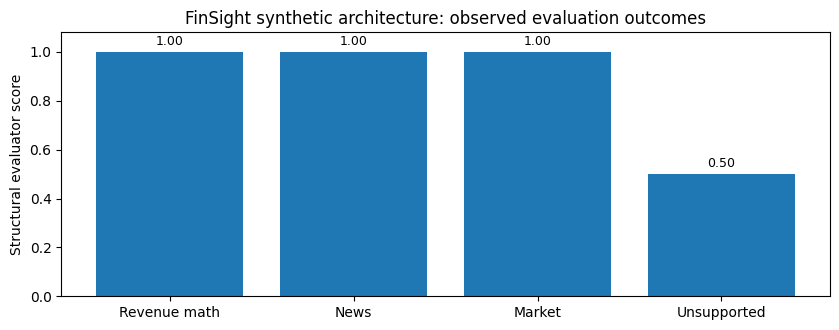

In [17]:
import matplotlib.pyplot as plt

names = ["Revenue math", "News", "Market", "Unsupported"]
eval_scores = [r["evaluation"]["score"] for r in demo_runs]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar(names, eval_scores)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Structural evaluator score")
ax.set_title("FinSight synthetic architecture: observed evaluation outcomes")
for i, v in enumerate(eval_scores):
    ax.text(i, min(v + 0.03, 1.05), f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 12. Real FinQA Retrieval and Model Evaluation — OPTIONAL NETWORKED RUN

**The following cell executes only when `RUN_REAL_FINQA=True`.** It downloads the original public FinQA `dev.json`, indexes text plus tables, runs retrieval evaluation, and optionally generates answers with a local Hugging Face model.

This is the section your team should run in **Colab** and then export as the *final submitted HTML/PDF* to demonstrate real data and real model inference. Results are generated at runtime; no outcomes are pre-filled.

For a 100-record dev subset, `hit@3` shows whether the correct record is found and `MRR@3` measures its rank. A separate numeric match metric measures answers. The lightweight model may perform poorly on multistep FinQA arithmetic; that result should be analyzed rather than concealed.

In [18]:
if RUN_REAL_FINQA:
    real_docs, qa_eval, finqa_meta = fetch_finqa("dev", limit=FINQA_RECORD_LIMIT)
    print("Official FinQA source and subset:", finqa_meta)
    print("First question:", qa_eval[0]["question"])
    print("First report context (preview):", real_docs[0].content[:500])

    model_backend = LocalLLM("google/flan-t5-small") if USE_LOCAL_HF_LLM else None
    finqa_agent = InvestmentResearchAgent(
        documents=real_docs,
        memory_path=str(Path(_demo_session.name) / "finqa_notes.json"),
        embedding_backend="sentence_transformer" if USE_SENTENCE_EMBEDDINGS else "tfidf",
        llm=model_backend,
    )
    print("Retriever:", finqa_agent.retriever.backend)
    print("Generation backend:", "google/flan-t5-small" if model_backend else "extractive demo baseline")
    retr_eval = retrieval_metrics(finqa_agent.retriever, qa_eval[:30], k=3)
    print("FinQA sampled retrieval metrics:", retr_eval)

    generated = []
    for record in qa_eval[:FINQA_EVAL_QUESTIONS]:
        predicted = finqa_agent.run("FINQA", record["question"], top_k=3)
        generated.append(predicted)
    qa_metrics = finqa_answer_accuracy(generated, qa_eval[:FINQA_EVAL_QUESTIONS])
    print("FinQA numeric QA metrics (educational, not official):",
          {k: v for k, v in qa_metrics.items() if k != "details"})
    display(pd.DataFrame([{
        "Question": q["question"], "Predicted": p["answer"],
        "Gold Answer (evaluation only)": q["gold_answer"],
        "Retriever Sources": ", ".join(x["id"] for x in p["retrieved"]),
        "Verified": p["evaluation"]["passed"],
    } for p, q in zip(generated, qa_eval[:FINQA_EVAL_QUESTIONS])]))
else:
    print("Not executed: set RUN_REAL_FINQA=True in a networked Colab environment.")
    print("The demonstration above must not be described as FinQA benchmark or LLM performance.")

Not executed: set RUN_REAL_FINQA=True in a networked Colab environment.
The demonstration above must not be described as FinQA benchmark or LLM performance.


## 13. Optional Live Market Tool (Read-only)

For a valid ticker in Colab, `fetch_yahoo_snapshot('AAPL')` fetches the most recent observed close and volume from Yahoo Finance through `yfinance`. **It does not trade or authorize transactions.** The default notebook does not run this network call; values are never invented. Real market data requires checking freshness, adjustments, currency, delays and terms of use.

In [19]:
RUN_LIVE_MARKET_API = False
if RUN_LIVE_MARKET_API:
    live_snapshot = fetch_yahoo_snapshot("AAPL")
    print("Live market snapshot (read only):", live_snapshot)
else:
    print("Live Yahoo Finance request not executed; offline DEMO price is fictional.")

Live Yahoo Finance request not executed; offline DEMO price is fictional.


## 14. Testing and Error Analysis

### Reproducible acceptance checks

The tests include: mathematical tool correctness and code-injection rejection, all three routes, five-stage news chain, retrieval, numerical calculation, unsupported-question abstention, iterative review, memory persistence, and FinQA answer-label isolation.

### Observed failure modes and mitigations

| Failure mode | Why it occurs | Mitigation and remaining limitation |
|---|---|---|
| Report context not retrieved | lexical/dense mismatch | compare top-k retrieval hit and MRR; tune chunks/embeddings |
| Text/table arithmetic | quantitative reasoning exceeds small model | use restricted calculator, validate operands, evaluate numeric answers |
| Unsupported question | source corpus lacks relevant information | abstain and request human review rather than inventing |
| Prompt injection in documents | untrusted context can contain instructions | keep retrieval as data, never grant model brokerage permissions |
| Incorrect source citation | generator may invent a citation | validate IDs; note ID validity alone is not semantic faithfulness |
| Stale market data | cached/fallback financial information | explicit timestamps, read-only live source, no automatic trading |
| Agent loop/cost escalation | uncontrolled feedback iterations | exactly one bounded refinement iteration |

The *structural evaluator score* is **not** financial factuality or official FinQA accuracy. The project demonstrates the difference explicitly.

In [20]:
# Standalone acceptance assertions (no network, no files outside this notebook).
assert round(safe_calculate("(250-200)/200*100"), 6) == 25.0
for unsafe in ("__import__('os')", "open('/etc/passwd')", "x + 1"):
    try:
        safe_calculate(unsafe)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Unsafe arithmetic unexpectedly accepted: {unsafe}")

assert detect_specialist("latest company news") == "news"
assert detect_specialist("stock price today") == "market"
assert detect_specialist("revenue growth") == "earnings"
assert not demo_runs[3]["evaluation"]["passed"]
assert len(demo_runs[3]["iterations"]) == 2
assert agent.memory.path.exists()
leak_check = {"id": "demo", "pre_text": ["sales are positive"],
              "post_text": [], "table": [["Revenue", "$10"]],
              "qa": {"question": "sample?", "exe_ans": "LEAKED_GOLD_VALUE",
                     "program": "LEAKED_ORACLE_PROGRAM"}}
converted = finqa_to_document(leak_check, split="test")
assert "LEAKED_GOLD_VALUE" not in converted.content
assert "LEAKED_ORACLE_PROGRAM" not in converted.content
print("ACCEPTANCE CHECKS PASSED: safe arithmetic, routes, abstention, "
      "iteration, memory persistence, gold-answer separation")

ACCEPTANCE CHECKS PASSED: safe arithmetic, routes, abstention, iteration, memory persistence, gold-answer separation


## 15. Conclusion, Academic Insights and Limitations

The project demonstrates a reproducible **multi-agent financial research architecture**, combining a planner, task-dependent tool calling, specialist routing, a five-stage news chain, self-evaluation/refinement, and persistent feedback. In the executed **synthetic** example, the earnings specialist computes a **25.00% revenue increase** using an auditable arithmetic tool, the news specialist summarizes supplied articles, the market specialist retrieves a clearly marked fictional quote, and an unsupported question triggers abstention and a second retrieval attempt.

### What we learned

1. **Agent design is a systems problem:** tool permissions, planner quality and bounded execution are as important as the language model.
2. **Retrieval and generation need separate evaluation:** a correct source record does not guarantee correct financial arithmetic.
3. **Grounding beats plausible extrapolation:** an abstention is preferable to inventing a missing number.
4. **External feedback is more reliable than unrestricted self-reflection:** calculator results and independent source checks are measurable.
5. **Memory should affect future behavior:** the agent changes retrieval depth after an unsuccessful prior run; this is policy adaptation, not weight training.

### Explicit limitations

- The embedded offline outputs use a **fictional classroom corpus**, not actual FinQA or market data.
- Actual Hugging Face inference and real FinQA metrics require switching on the optional code and running it in a network-enabled environment.
- The TF-IDF baseline is not equivalent to dense semantic retrieval; the true dense option uses MiniLM sentence embeddings.
- Lightweight FLAN-T5 is not guaranteed to solve multi-step financial calculations.
- Source-ID checking is weaker than claim-level faithfulness verification.
- Repository URL: https://github.com/karthik1997/finsight-multi-agent-financial-analysis. Team collaboration and individual commits must still be verified separately.

**For the highest-quality submission:** run the real FinQA + HF cells with all required outputs in Colab, inspect errors and include the verified GitHub URL when exporting the executed notebook to HTML or PDF. We do not claim performance that was not observed.

## 16. References (APA)

Chen, Z., Chen, W., Smiley, C., Shah, S., Borova, I., Langdon, D., Moussa, R., Beane, M., Huang, T.-H. K., Routledge, B. R., & Wang, W. Y. (2021). FinQA: A dataset of numerical reasoning over financial data. *Proceedings of the 2021 Conference on Empirical Methods in Natural Language Processing*, 3697–3711. https://aclanthology.org/2021.emnlp-main.300/

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W.-T., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401

National Institute of Standards and Technology. (2023). *Artificial intelligence risk management framework (AI RMF 1.0)* (NIST AI 100-1). https://doi.org/10.6028/NIST.AI.100-1

Shinn, N., Cassano, F., Gopinath, A., Narasimhan, K., & Yao, S. (2023). Reflexion: Language agents with verbal reinforcement learning. *Advances in Neural Information Processing Systems, 36*. https://arxiv.org/abs/2303.11366

Yao, S., Zhao, J., Yu, D., Du, N., Shafran, I., Narasimhan, K., & Cao, Y. (2023). ReAct: Synergizing reasoning and acting in language models. *International Conference on Learning Representations*. https://arxiv.org/abs/2210.03629

## 17. AI-Use Disclosure

AI tools were used to assist with **project scaffolding, implementation drafting, PEP 8-style organization, notebook authoring, testing strategy, documentation, and revision of explanatory text**. Contributions included initial drafts of the research-agent planner and specialist router, the financial-news preprocessing and synthesis chain, calculator and evaluator checks, feedback-memory persistence, FinQA ingestion and evaluation code, and reproducible offline acceptance tests.

**The team is responsible for independently reviewing, understanding, testing, modifying, and validating every component of the submitted work.** The submitted notebook includes locally executed outputs from a clearly labeled fictional demonstration; genuine FinQA benchmark scores, real market results, and downloaded model outputs are **not claimed**. AI-generated suggestions were reviewed as development aids, not treated as independently verified experimental findings.